# Week 6 — Classification I: Logistic Regression and K-Nearest Neighbours

## What is classification?

**Classification** means teaching a computer to put things into categories, using examples where we already know the right answer. Some everyday examples: is an email spam or not spam? Will a customer cancel their subscription or stay? Will a student pass or fail?

In this notebook we use one example throughout: **predicting whether a student passes, based on the hours they studied and their attendance.**

A few terms we will use again and again:

| Term | Meaning | In our example |
|---|---|---|
| **Observation** | One row of the data: one case we have information about | One student |
| **Features** (`X`) | The information we use to make the prediction (the inputs) | Hours studied, attendance (%) |
| **Target** (`y`) | The thing we want to predict (the answer) | Pass (`1`) or Fail (`0`) |
| **Model** | A rule, learned from data, that turns features into a prediction | Logistic Regression, KNN |
| **Training** | Letting the model learn from examples where the answer is known | `model.fit(...)` |

## The two methods in one sentence each

- **Logistic Regression** draws a dividing line between the groups and uses it to estimate the *probability* that a student passes.
- **K-Nearest Neighbours (KNN)** looks at the most similar students we already know about and goes with the majority outcome ("ask your neighbours").

By the end, you should be able to:
- train Logistic Regression and KNN classifiers.
- explain why scaling matters for KNN.
- compare test accuracy and visualise decision boundaries.

The idea is that you implement these methods on this test dataset as a warm-up before applying it on your own datasets.

## 1. Import the libraries
Like previous lectures, we also set `RANDOM_STATE = X`. Some steps (such as splitting the data) involve random choices. Fixing this "seed" makes the random choices the same every time, so everyone running the notebook gets the same results. The number 42 itself is arbitrary; any number works.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

## 2. Load example dataset

To keep the notebook self-contained, we have generated synthetic data. The values are illustrative, not real student records.

The data is stored in a CSV file (a plain-text table). We load it into a pandas DataFrame called `df`. Each **row** is one student and each **column** is one piece of information about them:

- **Features (`X`)**: `study_hours` (hours studied) and `attendance` (percentage of classes attended)
- **Target (`y`)**: `passed` (`1` = Pass, `0` = Fail)

The target was generated with some randomness, so the classes will overlap rather than being perfectly separable. This is realistic: two students with similar study habits can still have different outcomes.

`df.head()` shows the first five rows so we can check that the data loaded correctly.

In [2]:
df = pd.read_csv("../data/student_pass_fail.csv")

df.head()

,study_hours,attendance,passed
0,9.287473,88.912860,1
1,5.266541,86.793111,1
2,10.303175,50.121648,1
3,8.368416,69.500023,1
4,1.130128,74.391028,0


## 3. Explore the data

In [3]:
class_names = {0: "Fail", 1: "Pass"}

fig, ax = plt.subplots(figsize=(8, 5))
for label, name in [(0, "Fail"), (1, "Pass")]:
    subset = df[df["passed"] == label]
    ax.scatter(subset["study_hours"], subset["attendance"], label=name, alpha=0.8)

ax.set_xlabel("Hours studied")
ax.set_ylabel("Attendance (%)")
ax.set_title("Student outcomes: Pass or Fail?")
ax.legend()
plt.show()

df["passed"].value_counts().rename(index=class_names)

<Figure size 800x500 with 1 Axes>

passed
Fail    134
Pass    106
Name: count, dtype: int64

## 4. Define `X` and `y`, then split the data

`X` contains the input features (hours studied and attendance). `y` contains the target we want to predict (pass or fail).

### What does `stratify=y` do?

The split is random. By chance, a random split could put a very different share of passing students in the training set and in the test set. For example, if 60% of all students pass, we might end up with 70% passes in training but only 40% in the test set. That would make the comparison unfair.

**Stratification** prevents this. It means "split randomly, but keep the proportion of each class (Pass/Fail) about the same in both sets". If 60% of all students pass, then about 60% of the training set and about 60% of the test set will pass too.

The cell below also prints the proportions so you can check this yourself.

`random_state=RANDOM_STATE` makes the random split reproducible.

In [4]:
X = df[["study_hours", "attendance"]]
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

# Share of Pass/Fail in each group; stratify=y keeps these similar
pd.DataFrame({
    "All students": y.value_counts(normalize=True),
    "Training set": y_train.value_counts(normalize=True),
    "Test set": y_test.value_counts(normalize=True)
}).rename(index=class_names).round(2)

Training observations: 180
Test observations: 60


,All students,Training set,Test set
passed,,,
Fail,0.56,0.56,0.57
Pass,0.44,0.44,0.43


## 5. Train a Logistic Regression classifier

### The idea

Despite its name, Logistic Regression is used for **classification**. It works in two steps:

1. It combines the features into a single score, giving each feature a weight. For example, "more study hours and higher attendance push the score up". The model learns these weights from the training data.
2. It converts that score into a **probability** between 0 and 1 (using an S-shaped curve): the model's estimated chance that the student passes. A value close to 1 means the model is confident the student passes; a value close to 0 means it is confident the student fails.

To get a final answer (Pass or Fail), we apply a **threshold**: a cut-off on the probability. By convention the threshold is 0.5, so a probability of 0.5 or more is classified as Pass (`1`) and anything lower as Fail (`0`). This is a choice, not a rule of nature. We could use a different threshold; for example, if we wanted to be more careful before predicting Pass, we could require a probability of at least 0.8.

Geometrically, the 2 dimensional model draws a **straight line** through the plot of the features: students on one side are predicted to pass, students on the other side to fail.

### Scaling and pipelines

Hours studied (0 to 12) and attendance (35 to 100) are measured on very different scales. **Scaling** with `StandardScaler` rewrites each feature so that it is centred around 0 and has a comparable spread. This is not strictly necessary for Logistic Regression, but it helps the learning process and makes the weights comparable.

A **pipeline** chains steps together: first scale, then classify. The scaler learns its averages from the training data only. Using the test set for this would leak information about the "unseen" data into the model, which would make our test unfair (this is called *data leakage* as we covered in our preprocessing lecture).

### The key commands below

- `fit(X_train, y_train)`: the model *learns* from the training examples.
- `predict(X_test)`: the model gives a predicted class (0 or 1) for each test student.
- `predict_proba(X_test)`: the model gives the probabilities behind those predictions. We keep column `[:, 1]`, the probability of Pass.
- **Accuracy**: the share of test students classified correctly. For example, 0.80 means 80 out of every 100 predictions were right.

In [5]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)

log_reg.fit(X_train, y_train)

log_predictions = log_reg.predict(X_test)
log_probabilities = log_reg.predict_proba(X_test)[:, 1]

print("First 10 predicted classes:", log_predictions[:10])
print("First 10 probabilities of Pass:", np.round(log_probabilities[:10], 2))
print("Test accuracy:", round(accuracy_score(y_test, log_predictions), 3))

First 10 predicted classes: [1 0 1 1 1 0 0 0 0 0]
First 10 probabilities of Pass: [0.66 0.19 0.9  0.72 0.83 0.07 0.34 0.29 0.2  0.33]
Test accuracy: 0.833


### Interpret one prediction

A probability and a predicted class are not the same thing. The class is obtained by applying a threshold to the probability (0.5 by convention). For instance, a probability of 0.51 and a probability of 0.99 both give "Pass", but the model is far more confident in the second case.

The cell below shows one student from the test set: their features, what actually happened, the model's probability, and the model's final prediction. Notice that the model can be wrong, especially when the probability is close to the threshold.

**Try it:** Change the index `i` below to inspect another test observation. Can you find a student the model got wrong?

In [6]:
i = 0
print("Features:")
display(X_test.iloc[[i]])
print("Actual class:", class_names[int(y_test.iloc[i])])
print("Probability of Pass:", round(float(log_probabilities[i]), 3))
print("Predicted class at threshold 0.5:", class_names[int(log_predictions[i])])

Features:


,study_hours,attendance
2,10.303175,50.121648


Actual class: Pass
Probability of Pass: 0.656
Predicted class at threshold 0.5: Pass


## 6. Train a K-Nearest Neighbours classifier

### The idea

KNN is based on a simple principle: **similar students tend to have similar outcomes**. To predict for a new student:

1. Measure how far the new student is from every student in the training set (using their hours studied and attendance).
2. Pick the `k` closest students, their "nearest neighbours". Here `k = 5`.
3. Look at the neighbours' outcomes and take a **majority vote**. If 4 of the 5 neighbours passed, predict Pass.

KNN does not learn weights or draw a line. It simply stores the training data and looks things up when asked. The choice of `k` is up to us; we explore it in section 9.

### Why scaling matters here

"Distance" depends on the units of the features. Attendance ranges roughly from 35 to 100 (a spread of about 65), while study hours range from 0 to 12 (a spread of about 12). Without scaling, a difference of 10 percentage points in attendance would count the same as a difference of 10 hours of study, even though 10 hours is a huge difference and 10 percentage points is not. Attendance would dominate the distance, and study hours would be nearly ignored.

Scaling puts both features on a comparable footing, so each contributes fairly. As before, the pipeline fits the scaler on training data only.

In [7]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)
knn_predictions = knn.predict(X_test)

print("First 10 predicted classes:", knn_predictions[:10])
print("Test accuracy:", round(accuracy_score(y_test, knn_predictions), 3))

First 10 predicted classes: [1 0 1 1 1 0 0 0 0 0]
Test accuracy: 0.75


## 7. Compare the two models

We evaluate both models on exactly the same test observations, so the comparison is fair. **Accuracy** is the proportion of test observations classified correctly. It is useful for this introduction, although it is not sufficient for every real classification problem (for example, when one class is very rare).

Keep in mind that the test set is fairly small, so a difference of a percentage point or two may just be luck of the split rather than a real difference between the models.

In [8]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN (k=5)"],
    "Test accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, knn_predictions)
    ]
}).sort_values("Test accuracy", ascending=False)

results

,Model,Test accuracy
0,Logistic Regression,0.833333
1,KNN (k=5),0.750000


### Accuracy is just the first step

Accuracy gives one number for "how often was the model right?", but that number hides important details. Next session, we will learn more ways to evaluate and compare our models.

Here are some questions that accuracy alone cannot answer:

- **What kinds of mistakes does the model make?** Predicting Pass for a student who fails and predicting Fail for a student who passes are both errors, but they may not be equally costly. For example, if we used the model to decide which students need extra support, missing a student who is at risk is probably worse than offering support to a student who did not need it.
- **Is the model good on the rarer class?** Imagine 95% of students pass. A "model" that always predicts Pass would be 95% accurate, yet it would never identify a single student who fails.
- **Can we trust a single test set?** With a small test set, one lucky or unlucky split can change the accuracy noticeably. We need ways to check that a result is stable and not just chance.

Tools such as the confusion matrix and cross-validation help us answer these questions. For now, treat the accuracy values above as a first, rough comparison.

## 8. Visualise the decision boundaries

A **decision boundary** is the border between the region where a model predicts "Fail" and the region where it predicts "Pass". To draw it, we ask the model to predict a class for every point on a fine grid across the plot, and colour the background by the answer. The dots are the training students.

How to read the plots:
- A dot sitting in a region of a different colour is a student the model gets wrong.
- The boundary shows *how the model thinks*, not just how well it scores.

What to expect:
- Logistic Regression produces a **straight-line** boundary.
- KNN can produce a **curvy, irregular** boundary that follows local neighbourhoods of students.

These plots are for understanding model behaviour; performance should still be evaluated on held-out data.

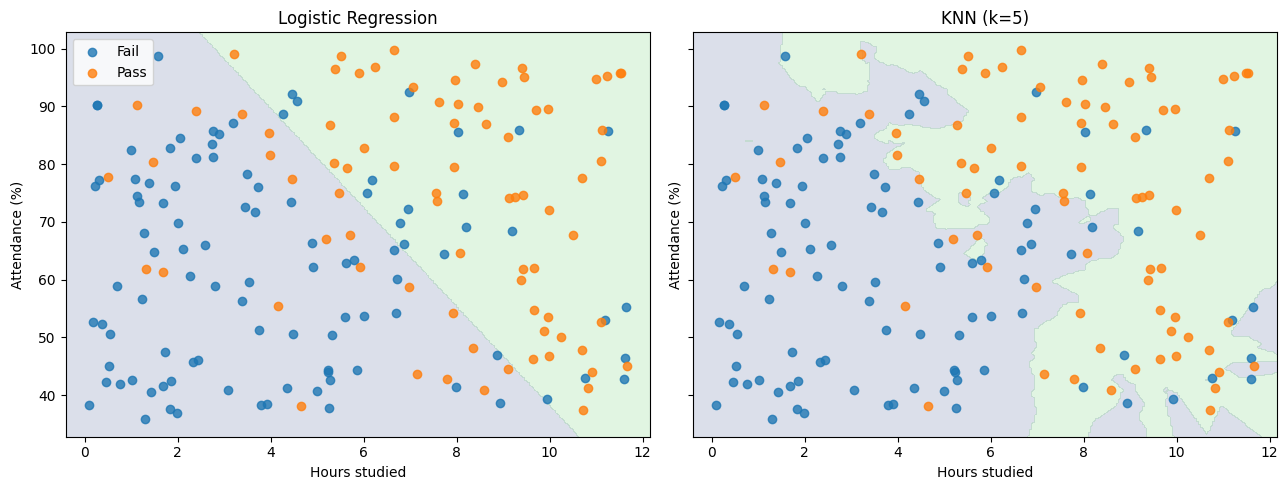

In [9]:
def plot_decision_boundary(model, X_train, y_train, title, ax):
    x_min, x_max = X_train["study_hours"].min() - 0.5, X_train["study_hours"].max() + 0.5
    y_min, y_max = X_train["attendance"].min() - 3, X_train["attendance"].max() + 3
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = pd.DataFrame({
        "study_hours": xx.ravel(),
        "attendance": yy.ravel()
    })
    zz = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5])
    for label, name in [(0, "Fail"), (1, "Pass")]:
        subset = X_train.loc[y_train == label]
        ax.scatter(subset["study_hours"], subset["attendance"], label=name, alpha=0.8)
    ax.set_xlabel("Hours studied")
    ax.set_ylabel("Attendance (%)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
plot_decision_boundary(log_reg, X_train, y_train, "Logistic Regression", axes[0])
plot_decision_boundary(knn, X_train, y_train, "KNN (k=5)", axes[1])
axes[0].legend()
plt.tight_layout()
plt.show()

## 9. What changes when we change `k`?

In KNN, `k` is the number of neighbours that vote. It is a setting we choose ourselves, not something the model learns.

- **Small `k` (e.g. 1)**: the prediction depends on just one neighbour, so the model reacts to every individual student, including unusual ones and random noise. The boundary becomes very irregular. The model can fit the training data almost perfectly but may not work well on new students. This is called **overfitting**.
- **Large `k` (e.g. 20)**: many neighbours vote, so individual unusual students have little influence. The boundary becomes smooth, but if `k` is too large the model may ignore genuine local patterns (**underfitting**).

Train KNN with different values of `k` and compare the test accuracy and decision boundaries.

**Before running the cell, predict:** Which value of `k` will produce the most irregular boundary? Which will produce the smoothest?

In [10]:
k_values = [1, 5, 20]
knn_models = {}
k_results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    knn_models[k] = model
    k_results.append({
        "k": k,
        "Test accuracy": accuracy_score(y_test, predictions)
    })

pd.DataFrame(k_results)

,k,Test accuracy
0,1,0.733333
1,5,0.750000
2,20,0.733333


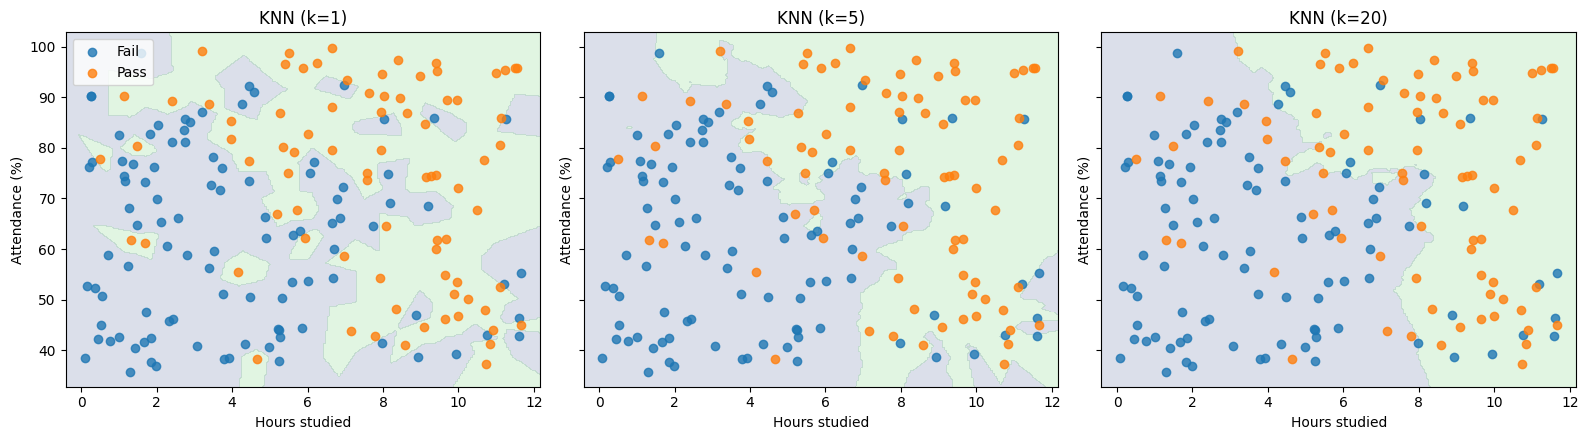

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, k in zip(axes, k_values):
    plot_decision_boundary(knn_models[k], X_train, y_train, f"KNN (k={k})", ax)
axes[0].legend()
plt.tight_layout()
plt.show()

### Optional extension
Change the test-set size or the random seed and compare the results. Does the ranking of the models stay the same?

## Key takeaways

### Logistic Regression vs KNN

| | **Logistic Regression** | **K-Nearest Neighbours (KNN)** |
|---|---|---|
| **Main idea** | Learns a weight for each feature and combines them into a score | Finds the `k` most similar training observations and takes a majority vote |
| **What is learned** | Weights (one per feature), learned during training | Nothing: it stores the training data and looks things up at prediction time |
| **Output** | A probability of the positive class, then a class using a threshold (0.5 by convention) | A class from a vote among the neighbours |
| **Decision boundary** | A straight line (in 2 features) | Can be curvy and irregular, following local neighbourhoods |
| **Setting we choose** | The threshold (and other settings we did not use here) | `k`, the number of neighbours |
| **Effect of that setting** | Moving the threshold changes how cautious the model is about predicting Pass | Small `k`: irregular boundary, risk of overfitting. Large `k`: smooth boundary, risk of underfitting |
| **Scaling the features** | Helpful, but not essential | Important: distances depend on units, so unscaled features can dominate |
| **Interpretability** | The weights show how each feature pushes the prediction up or down | Easy to explain ("students like this one passed"), but there are no weights to inspect |
| **Prediction speed** | Fast | Slower on large datasets, since it compares against the stored training data |

